# LAB 09 — Bias, Variance and Imbalanced Data
## Student Information
Name: Abdul Hussain
Student ID: 023-24-0286
Section: H
GitHub: https://github.com/AbdulHussainLehri/ML_Week9
Kaggle: https://www.kaggle.com/abdulhussainbrohi
Dataset: Stroke Prediction Dataset (Kaggle)
Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

> Golden rule used throughout: anything that learns from data (imputer, scaler, resampler, threshold) is learned from the **TRAIN** data only. `SEED = 42` everywhere.

## Part 0 — Setup and the Data

In [1]:
# pip install imbalanced-learn   (run once in Colab if needed)
import os, glob, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 100

In [2]:
# ---- 0.2 Load the CSV and explore
candidates = (["healthcare-dataset-stroke-data.csv", "/content/healthcare-dataset-stroke-data.csv"]
              + glob.glob("*stroke*.csv") + glob.glob("/content/*stroke*.csv")
              + glob.glob("/mnt/user-data/uploads/*stroke*.csv"))
DATA_PATH = next(p for p in candidates if os.path.exists(p))
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
miss = df.isna().sum()
print("\nColumns with missing values:\n", miss[miss > 0])
print("\nGender value counts:\n", df["gender"].value_counts())
vc = df["stroke"].value_counts()
print("\nStroke = 1 : %d (%.2f%%)" % (vc[1], 100 * vc[1] / len(df)))
print("Stroke = 0 : %d (%.2f%%)" % (vc[0], 100 * vc[0] / len(df)))

Shape: (5110, 12)

Columns with missing values:
 bmi    201
dtype: int64

Gender value counts:
 gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke = 1 : 249 (4.87%)
Stroke = 0 : 4861 (95.13%)


In [3]:
# ---- 0.3 Clean: drop id, drop the 1-row gender category, one-hot encode text columns
df = df.drop(columns="id")
print("Rows with gender == 'Other':", (df["gender"] == "Other").sum(), "-> removed")
df = df[df["gender"] != "Other"].reset_index(drop=True)

X = pd.get_dummies(df.drop(columns="stroke"), drop_first=True, dtype=int)
y = df["stroke"]
print("Feature matrix:", X.shape)
print(list(X.columns))

Rows with gender == 'Other': 1 -> removed
Feature matrix: (5109, 15)
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Male', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


In [4]:
# ---- 0.4 Split 80/20 (stratified), impute median from TRAIN only, scale (fit on TRAIN only)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

num_cols = ["age", "avg_glucose_level", "bmi"]
train_median = X_train[num_cols].median()          # learned from TRAIN only
print("Missing before imputation  train:", int(X_train.isna().sum().sum()),
      "| test:", int(X_test.isna().sum().sum()))
X_train = X_train.fillna(train_median)
X_test = X_test.fillna(train_median)               # test is filled with the TRAIN median
print("Missing after imputation   train:", int(X_train.isna().sum().sum()),
      "| test:", int(X_test.isna().sum().sum()))

scaler = StandardScaler().fit(X_train)             # fitted on TRAIN only
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# ---- 0.5 stroke cases per split
print("\nTrain rows: %d | strokes: %d (%.2f%%)" % (len(y_train), y_train.sum(), 100 * y_train.mean()))
print("Test  rows: %d | strokes: %d (%.2f%%)" % (len(y_test), y_test.sum(), 100 * y_test.mean()))

Missing before imputation  train: 163 | test: 38
Missing after imputation   train: 0 | test: 0

Train rows: 4087 | strokes: 199 (4.87%)
Test  rows: 1022 | strokes: 50 (4.89%)


**Answer 0(a) — Imbalance and stratification**

The data is heavily imbalanced: only **249 of 5,110 patients (4.87%)** had a stroke, against 4,861 (95.13%) who did not, roughly **1 stroke for every 20 healthy patients**. I used `stratify=y` so that train and test keep the same stroke rate (train: 199 strokes = 4.87%, test: 50 strokes = 4.89%). With a plain random split the test set could easily end up with, say, 35 or 65 strokes, or even far fewer, and then the results would depend on luck rather than on the model. Even in my stratified split the test set has only **50 stroke patients**, so every metric that involves the positive class (recall, precision, PR AUC) is noisy: **one patient changes recall by 2 percentage points**. If the test set had only a handful of strokes, recall could jump from 0% to 40% just because of which 5 patients were selected.

*Cleaning notes:* only `bmi` has missing values (201 rows, filled with the train median); the `gender = Other` category has a single row, so it can neither be learned nor tested and was removed (5,109 rows remain, 15 features after one-hot encoding).

## Part 1 — The Accuracy Trap

Baseline (always 'no stroke') accuracy: 0.9511


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Baseline (majority),0.951,0.0,0.00,0.000,0.500,0.049
LogReg (default),0.952,1.0,0.02,0.039,0.839,0.269


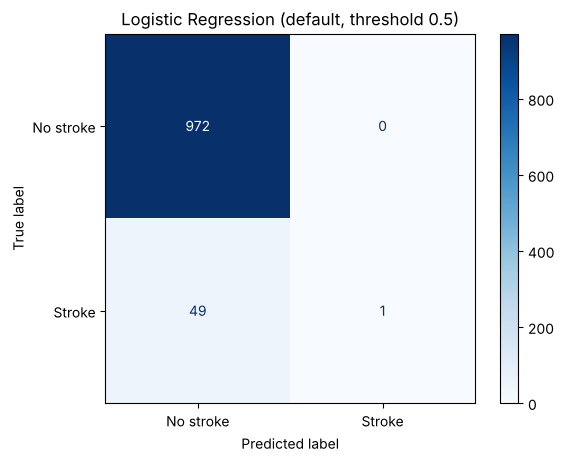

Confusion matrix [[TN FP],[FN TP]]:
 [[972   0]
 [ 49   1]]


In [5]:
# ---- reusable helper: returns the six metrics
def evaluate(model, Xtr, ytr, Xte, yte, fit=True, threshold=0.5):
    """Fit (optionally) and return Accuracy, Precision, Recall, F1, ROC AUC, PR AUC on the test set."""
    if fit:
        model.fit(Xtr, ytr)
    proba = model.predict_proba(Xte)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, zero_division=0),
            "Recall": recall_score(yte, pred, zero_division=0),
            "F1": f1_score(yte, pred, zero_division=0),
            "ROC_AUC": roc_auc_score(yte, proba),
            "PR_AUC": average_precision_score(yte, proba)}

# ---- 1.1 majority-class baseline
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base_acc = accuracy_score(y_test, dummy.predict(X_test))
print("Baseline (always 'no stroke') accuracy: %.4f" % base_acc)

# ---- 1.2 default Logistic Regression on scaled data
lr0 = LogisticRegression(max_iter=1000, random_state=SEED)
res_lr0 = evaluate(lr0, X_train_s, y_train, X_test_s, y_test)
res_dummy = evaluate(dummy, X_train, y_train, X_test, y_test, fit=False)
part1 = pd.DataFrame({"Baseline (majority)": res_dummy, "LogReg (default)": res_lr0}).T
display(part1)

cm0 = confusion_matrix(y_test, lr0.predict(X_test_s))
ConfusionMatrixDisplay(cm0, display_labels=["No stroke", "Stroke"]).plot(cmap="Blues")
plt.title("Logistic Regression (default, threshold 0.5)"); plt.show()
print("Confusion matrix [[TN FP],[FN TP]]:\n", cm0)

**Answer 1(a) — Baseline vs Logistic Regression**

The "always say *no stroke*" baseline reaches **accuracy 0.9511** without learning anything. The default Logistic Regression reaches **0.9521**, which is just **one extra correct patient** out of 1,022 (973 vs 972). Its accuracy looks excellent, but it is practically the same as doing nothing, so the model has not shown any usable skill *according to accuracy*. Accuracy is dominated by the 95% healthy patients and therefore cannot tell a useful model from a useless one on this dataset.

**Answer 1(b) — Confusion matrix and which numbers to trust**

The confusion matrix is `[[972, 0], [49, 1]]`: the model found **1 of the 50 strokes** (recall = 0.02) and missed 49. Its precision of 1.00 is meaningless because it is based on a single flagged patient. The F1 of 0.039 shows the real picture. In the hospital's situation a **false negative is a stroke patient sent home as "low risk"**, with possibly fatal or disabling consequences and no preventive treatment, so it is by far the most costly error. We should therefore trust **recall, precision/PR AUC and F1** (and ROC AUC for the ranking quality: 0.839 here), looked at together with the confusion matrix, and **not accuracy**. Note that the model's ranking is actually decent (ROC AUC 0.839, PR AUC 0.269 vs a no-skill 0.049); it is the default 0.5 cut-off that makes it useless. This is picked up again in Part 3.

## Part 2 — Underfitting, Overfitting, Bias and Variance
From here on, ROC AUC is the cross-validation score.

### Task 2.1 — Validation curve

,Train_AUC,CV_AUC
max_depth,,
1,0.717,0.732
2,0.821,0.817
3,0.838,0.816
4,0.858,0.818
5,0.876,0.792
6,0.903,0.759
7,0.928,0.738
8,0.949,0.714
9,0.968,0.681


Best depth by CV AUC: 4 -> CV AUC = 0.8180


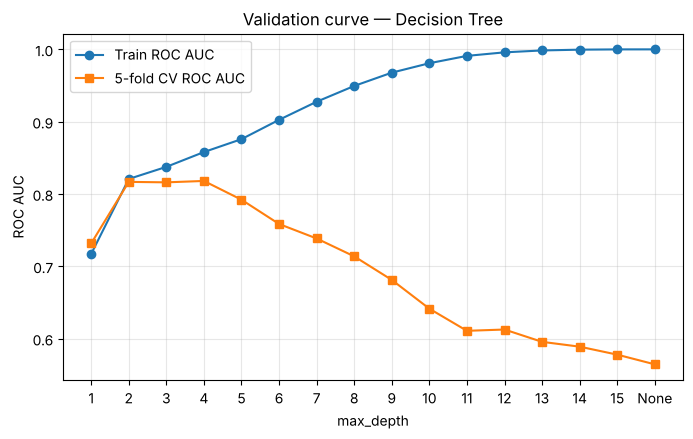

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depths = list(range(1, 16)) + [None]
rows = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    cv_auc = cross_val_score(tree, X_train, y_train, cv=skf, scoring="roc_auc").mean()
    tree.fit(X_train, y_train)
    tr_auc = roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1])
    rows.append({"max_depth": "None" if d is None else d, "Train_AUC": tr_auc, "CV_AUC": cv_auc})
vc_df = pd.DataFrame(rows).set_index("max_depth")
display(vc_df)

best_depth = vc_df["CV_AUC"].idxmax()
print("Best depth by CV AUC:", best_depth, "-> CV AUC = %.4f" % vc_df["CV_AUC"].max())

plt.figure(figsize=(8, 4.5))
xs = list(range(len(vc_df)))
plt.plot(xs, vc_df["Train_AUC"], "o-", label="Train ROC AUC")
plt.plot(xs, vc_df["CV_AUC"], "s-", label="5-fold CV ROC AUC")
plt.xticks(xs, vc_df.index.astype(str))
plt.xlabel("max_depth"); plt.ylabel("ROC AUC"); plt.title("Validation curve — Decision Tree")
plt.legend(); plt.grid(alpha=.3); plt.show()

### Task 2.2 — Learning curves

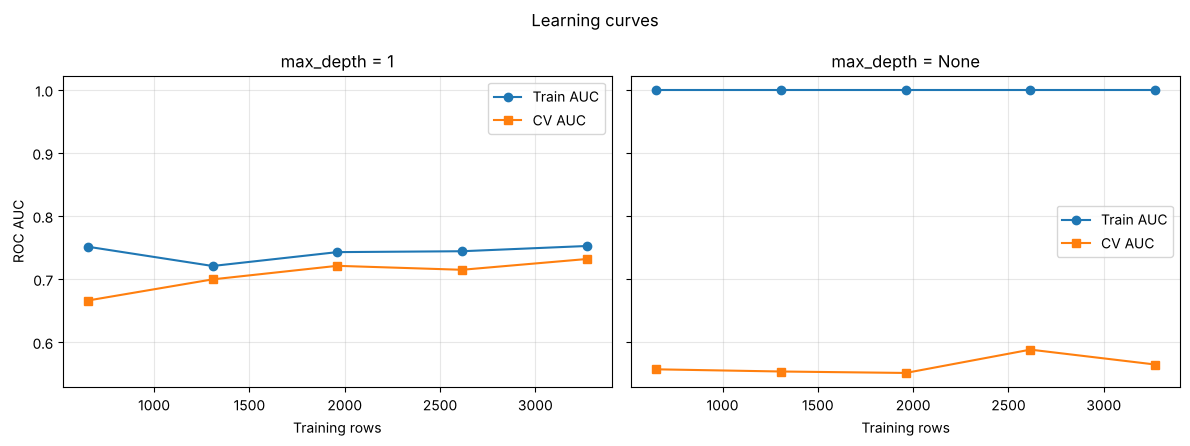

Train_AUC  CV_AUC
max_depth train_rows                   
1         653             0.751   0.666
          1307            0.721   0.699
          1961            0.743   0.721
          2615            0.744   0.715
          3269            0.752   0.732
None      653             1.000   0.557
          1307            1.000   0.553
          1961            1.000   0.551
          2615            1.000   0.588
          3269            1.000   0.564

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
lc_summary = []
for ax, d in zip(axes, [1, None]):
    sizes, tr_sc, va_sc = learning_curve(
        DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train,
        scoring="roc_auc", train_sizes=np.linspace(0.2, 1.0, 5), cv=skf, shuffle=True, random_state=SEED)
    ax.plot(sizes, tr_sc.mean(axis=1), "o-", label="Train AUC")
    ax.plot(sizes, va_sc.mean(axis=1), "s-", label="CV AUC")
    ax.set_title("max_depth = %s" % d); ax.set_xlabel("Training rows"); ax.grid(alpha=.3); ax.legend()
    lc_summary.append(pd.DataFrame({"train_rows": sizes, "Train_AUC": tr_sc.mean(axis=1),
                                    "CV_AUC": va_sc.mean(axis=1)}).assign(max_depth=str(d)))
axes[0].set_ylabel("ROC AUC")
plt.suptitle("Learning curves"); plt.tight_layout(); plt.show()
display(pd.concat(lc_summary).set_index(["max_depth", "train_rows"]))

### Task 2.3 — Measure variance directly

In [8]:
n_boot = 40
rng = np.random.default_rng(SEED)
var_rows = []
for d in [1, 3, None]:
    probs = np.zeros((n_boot, len(X_test)))
    single_aucs = []
    for b in range(n_boot):
        idx = rng.choice(len(X_train), len(X_train), replace=True)       # bootstrap rows
        t = DecisionTreeClassifier(max_depth=d, random_state=SEED)
        t.fit(X_train.iloc[idx], y_train.iloc[idx])
        probs[b] = t.predict_proba(X_test)[:, 1]
        single_aucs.append(roc_auc_score(y_test, probs[b]))
    var_rows.append({"max_depth": "None" if d is None else d,
                     "Mean prediction variance": probs.var(axis=0).mean(),
                     "Mean single-tree test AUC": np.mean(single_aucs),
                     "Std of single-tree AUC": np.std(single_aucs),
                     "AUC of averaged prediction": roc_auc_score(y_test, probs.mean(axis=0))})
var_df = pd.DataFrame(var_rows).set_index("max_depth")
display(var_df)

,Mean prediction variance,Mean single-tree test AUC,Std of single-tree AUC,AUC of averaged prediction
max_depth,,,,
1,6.799e-04,0.762,0.016,0.813
3,1.668e-03,0.796,0.012,0.834
None,4.197e-02,0.555,0.026,0.757


**Answer 2(a) — Validation curve**

* **Underfitting (high bias):** depth 1: train AUC 0.717 and CV AUC 0.732. Both are low and close together, so the tree is too simple to capture the pattern (depth 1 uses a single split, almost certainly on age).
* **Good zone:** depths 2-4. Depth 3: train 0.838 / CV 0.816; depth 4 has the **best CV AUC = 0.818** (train 0.858).
* **Overfitting (high variance):** from depth 5 on the train AUC keeps growing while CV AUC falls: depth 5: 0.876 / 0.792; depth 10: 0.981 / 0.641; **depth None: train 1.000 / CV 0.564**, which is barely better than random guessing (0.5). The gap between the curves is the signature of overfitting.

**Choice:** the best CV score is at depth 4 (0.818), but depths 2, 3 and 4 are within 0.002 of each other, so I would choose the simpler **depth 3** (CV 0.816, train/CV gap of only 0.022 against 0.040 at depth 4), which is also the depth used in the rest of the lab.

**Answer 2(b) — Learning curves**

* **High bias (depth 1):** train AUC (about 0.72-0.75) and CV AUC (0.666 -> 0.732) are *both low* and converge to nearly the same value (gap about 0.02 at 3,269 rows). The curves have flattened, so **more training rows will not fix it**: the model is simply too simple. More capacity (a deeper tree) is the cure.
* **High variance (depth None):** train AUC is **1.000** at every size while CV AUC stays around 0.55-0.59 (0.557 at 653 rows vs 0.564 at 3,269 rows). The gap of about 0.44 is huge and barely shrinks. More data can in principle narrow such a gap, but here five times more data barely moved it, so it is not a practical fix. Constraining the model (limit depth, `min_samples_leaf`) or averaging many trees (bagging) helps much more.

**Answer 2(c) — Variance table**

| max_depth | mean prediction variance | mean single-tree AUC | AUC of averaged prediction |
|---|---|---|---|
| 1 | 0.00068 | 0.762 | 0.813 |
| 3 | 0.00167 | 0.796 | 0.834 |
| None | 0.04197 | 0.555 | 0.757 |

Variance **increases sharply with depth**: depth None has about 25 times the variance of depth 3 and about 60 times that of depth 1, i.e. with a slightly different training sample the fully grown tree gives very different probabilities for the same patient. Averaging the 40 trees (bagging) improves the AUC in every case, but the gain is **tiny for low-variance trees (+0.05 at depth 1 and +0.04 at depth 3) and huge for the high-variance deep tree (0.555 -> 0.757, +0.20)**. This is exactly what Random Forest (Lab 4) does: it grows many deep, low-bias but high-variance trees on bootstrap samples (plus random feature subsets) and averages them, so the variance is cancelled while the bias stays low. (The averaged depth-None model, 0.757, is still worse than the averaged depth-3 model, 0.834: averaging cannot remove the fact that every unpruned tree has memorised noise, which is why the forest in Part 3 also uses `min_samples_leaf=5`.)

**Answer 2(d) — Bias-variance trade-off**

*Bias* is the error from a model being too simple to represent the true pattern; *variance* is the error from a model being so flexible that it follows the quirks of its particular training sample. Making a model more complex lowers bias but raises variance, and the best generalisation is at a sweet spot in between. **Depth 1** sits on the high-bias side (underfit: low variance 0.0007 but low AUC 0.76). **Depth 3** is close to the sweet spot (moderate variance 0.0017, best single-tree test AUC 0.796). **Depth None** is on the high-variance side (variance 0.042, train AUC 1.0 vs test AUC 0.555).

## Part 3 — ROC, AUC, Precision-Recall and Thresholds

### Task 3.1 — Compare models with curves

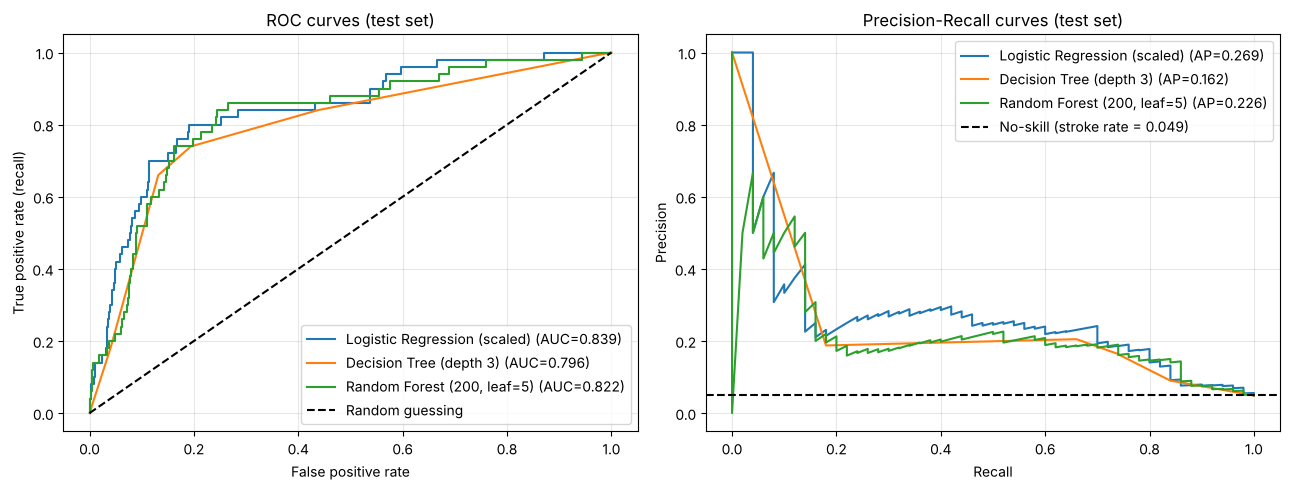

,ROC_AUC,PR_AUC
Logistic Regression (scaled),0.839,0.269
Decision Tree (depth 3),0.796,0.162
"Random Forest (200, leaf=5)",0.822,0.226


In [9]:
models3 = {
    "Logistic Regression (scaled)": (LogisticRegression(max_iter=1000, random_state=SEED), X_train_s, X_test_s),
    "Decision Tree (depth 3)": (DecisionTreeClassifier(max_depth=3, random_state=SEED), X_train, X_test),
    "Random Forest (200, leaf=5)": (RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                           random_state=SEED, n_jobs=-1), X_train, X_test),
}
test_proba = {}
for name, (m, Xtr_, Xte_) in models3.items():
    m.fit(Xtr_, y_train)
    test_proba[name] = m.predict_proba(Xte_)[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label="%s (AUC=%.3f)" % (name, roc_auc_score(y_test, p)))
ax[0].plot([0, 1], [0, 1], "k--", label="Random guessing")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate (recall)")
ax[0].set_title("ROC curves (test set)"); ax[0].legend(loc="lower right"); ax[0].grid(alpha=.3)

for name, p in test_proba.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label="%s (AP=%.3f)" % (name, average_precision_score(y_test, p)))
noskill = y_test.mean()
ax[1].axhline(noskill, color="k", ls="--", label="No-skill (stroke rate = %.3f)" % noskill)
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall curves (test set)"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

display(pd.DataFrame({n: {"ROC_AUC": roc_auc_score(y_test, p), "PR_AUC": average_precision_score(y_test, p)}
                      for n, p in test_proba.items()}).T)

### Task 3.2 — Choose a decision threshold (TRAIN data only)

Chosen threshold (from out-of-fold train probabilities): 0.0509
OOF recall at this threshold: 0.804 | OOF flag rate: 0.288

TEST  recall    : 0.820
TEST  precision : 0.135
Confusion matrix [[TN FP],[FN TP]]:
 [[710 262]
 [  9  41]]
Patients flagged: 303 of 1022 (29.6%) | false alarms: 262 | missed strokes: 9


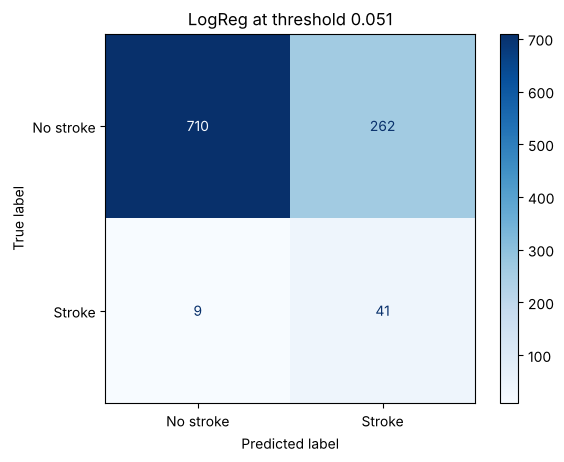

In [10]:
# out-of-fold probabilities on TRAIN only; scaler lives inside the pipeline so it is refit in every fold
lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
oof = cross_val_predict(lr_pipe, X_train, y_train, cv=skf, method="predict_proba")[:, 1]

fpr, tpr, thr_arr = roc_curve(y_train, oof)
ok = np.where(tpr >= 0.80)[0]
thr = thr_arr[ok[0]]              # thresholds are in decreasing order -> first hit = highest threshold
print("Chosen threshold (from out-of-fold train probabilities): %.4f" % thr)
print("OOF recall at this threshold: %.3f | OOF flag rate: %.3f" % (tpr[ok[0]], ((oof >= thr).mean())))

# apply to TEST probabilities of the Logistic Regression trained on the full scaled train set
p_lr = test_proba["Logistic Regression (scaled)"]
pred_thr = (p_lr >= thr).astype(int)
cm_thr = confusion_matrix(y_test, pred_thr)
tn, fp, fn, tp = cm_thr.ravel()
print("\nTEST  recall    : %.3f" % recall_score(y_test, pred_thr))
print("TEST  precision : %.3f" % precision_score(y_test, pred_thr))
print("Confusion matrix [[TN FP],[FN TP]]:\n", cm_thr)
print("Patients flagged: %d of %d (%.1f%%) | false alarms: %d | missed strokes: %d"
      % (pred_thr.sum(), len(y_test), 100 * pred_thr.mean(), fp, fn))
ConfusionMatrixDisplay(cm_thr, display_labels=["No stroke", "Stroke"]).plot(cmap="Blues")
plt.title("LogReg at threshold %.3f" % thr); plt.show()

**Interpretation of the curves.** Logistic Regression is the best model on both curves (ROC AUC 0.839, AP 0.269), then Random Forest (0.822, 0.226) and the depth-3 tree (0.796, 0.162). All three ROC curves are clearly above the diagonal. On the Precision-Recall chart all curves lie above the no-skill line (0.049), but precision drops quickly as recall grows. Using only the training data, the out-of-fold LR probabilities gave a threshold of **0.0509** (OOF recall 0.804). On the test set this threshold gives **recall 0.82 (41 of 50 strokes), precision 0.135**; 303 patients (29.6%) are flagged, of whom **262 are false alarms**, and 9 strokes are missed.

**Answer 3(a) — Low recall but high AUC**

Both are true because they measure different things. **ROC AUC measures ranking quality across all possible thresholds**: it is the probability that a randomly chosen stroke patient gets a higher score than a randomly chosen healthy patient (here 0.839). It does not depend on any particular cut-off. **Recall at 0.5 depends on one specific threshold.** Since only about 5% of patients have a stroke, even a good model gives most stroke patients a probability far below 0.5 (stroke patients are scored higher than healthy ones, but still low in absolute terms), so almost nobody crosses 0.5 and recall is 0.02. The 0.5 threshold is just one point on the ROC curve (the bottom-left corner here). Moving the threshold down to 0.051 moves along the same curve and raises recall to 0.82, without changing the AUC at all.

**Answer 3(b) — ROC or Precision-Recall?**

For this data the **Precision-Recall curve is more informative**. The ROC curve uses the false positive rate, whose denominator is the huge group of healthy patients (972 in the test set), so even 262 false alarms is only an FPR of about 27%, and the ROC curves look comfortably good (AUC 0.80-0.84) and close to each other. The PR curve shows what the hospital actually lives with: precision. The no-skill line is at the stroke rate **0.049**, and our best average precision is 0.269, which is about 5.5 times better than chance but still means most alerts are wrong, and the curves of the three models are separated more clearly (AP 0.269 / 0.226 / 0.162). The ROC diagonal at 0.5 would make the models seem far better than they are for the user.

**Answer 3(c) — The price of recall 0.82**

The price is **precision 0.135**: 303 patients (29.6% of everyone) are flagged to catch 41 strokes, so there are **262 false alarms, i.e. about 6.4 false alarms per stroke caught**, and 87% of the flagged patients are healthy.

* *Acceptable:* the follow-up for a flagged patient (a blood pressure/glucose check, a doctor's review) is cheap compared with an untreated stroke (death, disability, huge cost). Compared with the default threshold we catch 40 more strokes (41 vs 1) and miss only 9 instead of 49.
* *Not acceptable:* flagging almost 3 in 10 patients can overload clinics and cause anxiety, unnecessary tests and "alert fatigue", so staff may start ignoring the flags; and 9 strokes are still missed.

My view: it is acceptable **if the second-stage check is cheap and non-invasive**; if confirmation is expensive or risky, a higher threshold (less recall) should be negotiated with the hospital.

## Part 4 — Undersampling, Oversampling and SMOTE

### Task 4.1 — Compare the methods (resample TRAIN only)

In [11]:
def make_lr(**kw): return LogisticRegression(max_iter=1000, random_state=SEED, **kw)
def make_rf(**kw): return RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                 random_state=SEED, n_jobs=-1, **kw)
methods = {"No resampling": None,
           "class_weight=balanced": "cw",
           "Random undersampling": RandomUnderSampler(random_state=SEED),
           "Random oversampling": RandomOverSampler(random_state=SEED),
           "SMOTE": SMOTE(random_state=SEED)}
setups = {"LogReg": (make_lr, X_train_s, X_test_s), "RandomForest": (make_rf, X_train, X_test)}

rows41, store41 = [], {}
for mname, (maker, Xtr_, Xte_) in setups.items():
    for meth, sampler in methods.items():
        if sampler is None:
            Xr, yr, model = Xtr_, y_train, maker()
        elif sampler == "cw":
            Xr, yr, model = Xtr_, y_train, maker(class_weight="balanced")
        else:
            Xr, yr = sampler.fit_resample(Xtr_, y_train)       # TRAIN only; test untouched
            model = maker()
        r = evaluate(model, Xr, yr, Xte_, y_test)
        store41[(mname, meth)] = r
        rows41.append({"Model + method": f"{mname} + {meth}", "Train rows": len(yr),
                       "Train strokes": int(np.sum(yr)), **{k: r[k] for k in ["Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]}})
tab41 = pd.DataFrame(rows41).set_index("Model + method")
display(tab41)

,Train rows,Train strokes,Precision,Recall,F1,ROC_AUC,PR_AUC
Model + method,,,,,,,
LogReg + No resampling,4087,199,1.000,0.02,0.039,0.839,0.269
LogReg + class_weight=balanced,4087,199,0.135,0.80,0.231,0.840,0.260
LogReg + Random undersampling,398,199,0.125,0.82,0.216,0.835,0.234
LogReg + Random oversampling,7776,3888,0.133,0.80,0.229,0.838,0.265
LogReg + SMOTE,7776,3888,0.134,0.80,0.229,0.841,0.288
RandomForest + No resampling,4087,199,0.000,0.00,0.000,0.822,0.226
RandomForest + class_weight=balanced,4087,199,0.189,0.72,0.300,0.815,0.199
RandomForest + Random undersampling,398,199,0.105,0.84,0.187,0.820,0.203
RandomForest + Random oversampling,7776,3888,0.188,0.32,0.237,0.811,0.191


### Task 4.2 — The classic mistake (SMOTE before the split)

In [12]:
# WRONG ORDER: impute + SMOTE on ALL the data, then split, train, evaluate
X_all = X.fillna(X[num_cols].median())
X_wr, y_wr = SMOTE(random_state=SEED).fit_resample(X_all, y)
Xtr_w, Xte_w, ytr_w, yte_w = train_test_split(X_wr, y_wr, test_size=0.20, stratify=y_wr, random_state=SEED)
res_wrong = evaluate(make_rf(), Xtr_w, ytr_w, Xte_w, yte_w)

res_right = store41[("RandomForest", "SMOTE")]
cols = ["Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
tab42 = pd.DataFrame({"Correct: split first, SMOTE on train only": {**{c: res_right[c] for c in cols},
                                                                    "Test rows": len(y_test), "Test strokes": int(y_test.sum())},
                      "WRONG: SMOTE on all data, then split": {**{c: res_wrong[c] for c in cols},
                                                               "Test rows": len(yte_w), "Test strokes": int(yte_w.sum())}}).T
display(tab42)
print("After SMOTE on all data: %d rows, %d strokes (original had %d rows, %d strokes)"
      % (len(y_wr), y_wr.sum(), len(y), y.sum()))

,Precision,Recall,F1,ROC_AUC,PR_AUC,Test rows,Test strokes
"Correct: split first, SMOTE on train only",0.127,0.200,0.155,0.767,0.119,1022.0,50.0
"WRONG: SMOTE on all data, then split",0.929,0.942,0.936,0.981,0.976,1944.0,972.0


After SMOTE on all data: 9720 rows, 4860 strokes (original had 5109 rows, 249 strokes)


**Answer 4(a) — Logistic Regression: what changed and what did not**

*Changed:* the operating point. With no resampling, recall was 0.02 and precision 1.00 (1 flagged patient), F1 0.039. After class weighting, undersampling, oversampling or SMOTE, **recall rose to 0.80-0.82, precision fell to 0.125-0.135 and F1 rose to about 0.22-0.23**. *Not changed:* the ability to rank patients: **ROC AUC stayed at 0.835-0.841** for all methods (0.839 with no resampling), and PR AUC changed only slightly (0.234-0.288). The reason is that Logistic Regression is a simple, low-variance, almost linear model: rebalancing the classes mostly shifts its intercept (the prior), so the predicted probabilities all go up, and more patients cross the 0.5 line, but the order of the patients stays almost the same. It is in effect the same as lowering the threshold in Part 3 (which gave recall 0.82 / precision 0.135 too). Small differences (e.g. SMOTE PR AUC 0.288 vs 0.269, undersampling 0.234) are within what 50 test strokes can produce; undersampling is the weakest as it throws away about 3,700 of the 4,087 training rows.

**Answer 4(b) — Random Forest reacts differently**

Not at all in the same way. For LR all four rebalancing methods landed on almost the same recall (about 0.80). For Random Forest they differ widely: no resampling recall 0.00, `class_weight` 0.72 (precision 0.189, F1 0.300, the best F1 in the table), undersampling 0.84 (precision 0.105), but **random oversampling only 0.32 and SMOTE only 0.20**, and SMOTE also *lowers* the ranking quality (ROC AUC 0.822 -> 0.767, PR AUC 0.226 -> 0.119). One possible reason: oversampling and SMOTE create thousands of identical or near-identical minority rows (3,888 "strokes" built from 199 real ones), and a flexible forest can memorise these copies, building leaves that fit the training strokes perfectly but do not generalise, which is overfitting in the sense of Part 2. Class weighting and undersampling do not duplicate rows, so the forest does not memorise the same patients over and over. (The unresampled forest with `min_samples_leaf=5` gives probabilities that almost never reach 0.5, hence recall 0.)

**Answer 4(c) — Wrong order vs correct order**

| | Precision | Recall | F1 | ROC AUC | PR AUC |
|---|---|---|---|---|---|
| Correct (split first, SMOTE on train) | 0.127 | 0.200 | 0.155 | 0.767 | 0.119 |
| WRONG (SMOTE on all data, then split) | 0.929 | 0.942 | 0.936 | 0.981 | 0.976 |

The wrong-order numbers are amazing but **fake**. SMOTE builds each synthetic stroke by interpolating between a real stroke patient and one of its nearest stroke neighbours. If this is done before the split, the synthetic rows are scattered randomly into both train and test, so a synthetic test patient lies right on the line between real patients who are in the training set (and a real test patient was used to generate synthetic training rows which are its near-copies). **Information leaks from the test patients into the training data (through the interpolation) and from the training patients into the test set (the synthetic test rows are made of train patients).** The forest is then "tested" on near-duplicates of what it has seen. In addition, the wrong test set is artificially balanced (972 strokes out of 1,944 rows, 50%), so precision and PR AUC are measured against a 50% base rate instead of the real 4.9%, and they cannot represent real hospital performance. The correct result (recall 0.20, ROC 0.767) is the honest one.

**Answer 4(d) — My pick for the hospital**

I would pick **`class_weight='balanced'`** (or, equivalently for Logistic Regression, simply choosing the threshold as in Part 3). It is the simplest: one argument, no extra library, no change to the data, no synthetic patients, and no risk of leakage from resampling. It cost nothing in quality: LR with `class_weight` gave recall 0.80, precision 0.135, ROC AUC 0.840, as good as oversampling/SMOTE (recall 0.80, ROC AUC 0.838 / 0.841), and for Random Forest it gave the best F1 (0.300). Undersampling discards about 90% of the training rows (4,087 -> 398), which wastes information and makes the model less stable; oversampling and SMOTE double the training set (7,776 rows), cost more time, can make flexible models overfit (Random Forest recall dropped to 0.32 and 0.20) and, as Part 5 shows, can amplify label noise.

## Part 5 — Noisy Data

In [13]:
def model_zoo():
    return {"LogReg": make_lr(),
            "Tree d=3": DecisionTreeClassifier(max_depth=3, random_state=SEED),
            "Tree d=None": DecisionTreeClassifier(max_depth=None, random_state=SEED),
            "RandomForest": make_rf()}

def flip_labels(y_arr, frac, rng):
    """Flip `frac` of the labels at random (0->1, 1->0)."""
    y_new = np.asarray(y_arr).copy()
    n_flip = int(round(frac * len(y_new)))
    idx = rng.choice(len(y_new), n_flip, replace=False)
    y_new[idx] = 1 - y_new[idx]
    return y_new

def fit_score_zoo(Xtr_raw, ytr_arr, Xte_raw, scale_fit_on_train=True):
    """Train all 4 models and return test ROC AUC. LogReg gets a scaler fitted on the (possibly noisy) train data."""
    sc = StandardScaler().fit(Xtr_raw)
    out = {}
    for name, m in model_zoo().items():
        if name == "LogReg":
            m.fit(sc.transform(Xtr_raw), ytr_arr); p = m.predict_proba(sc.transform(Xte_raw))[:, 1]
        else:
            m.fit(Xtr_raw, ytr_arr); p = m.predict_proba(Xte_raw)[:, 1]
        out[name] = roc_auc_score(y_test, p)
    return out

### Task 5.1 — Label noise

,LogReg,Tree d=3,Tree d=None,RandomForest
label noise fraction,,,,
0.00,0.839,0.796,0.580,0.822
0.05,0.824,0.801,0.553,0.803
0.10,0.813,0.803,0.511,0.759
0.20,0.774,0.726,0.505,0.683


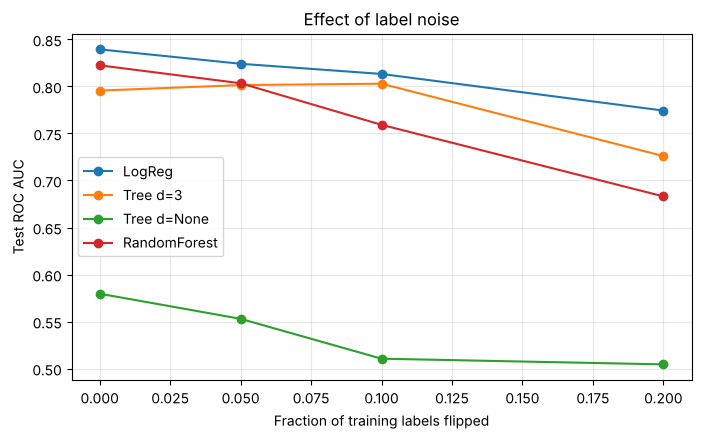

In [14]:
fracs = [0, 0.05, 0.10, 0.20]
label_rows = {}
for f in fracs:
    reps = 1 if f == 0 else 5
    runs = []
    for r in range(reps):
        rng = np.random.default_rng(SEED + r)
        y_noisy = flip_labels(y_train, f, rng)
        runs.append(fit_score_zoo(X_train, y_noisy, X_test))
    label_rows[f] = pd.DataFrame(runs).mean()
label_tab = pd.DataFrame(label_rows).T
label_tab.index.name = "label noise fraction"
display(label_tab)

label_tab.plot(marker="o", figsize=(8, 4.5))
plt.ylabel("Test ROC AUC"); plt.xlabel("Fraction of training labels flipped")
plt.title("Effect of label noise"); plt.grid(alpha=.3); plt.show()

### Task 5.2 — Feature noise

,LogReg,Tree d=3,Tree d=None,RandomForest
feature noise level (x std),,,,
0.0,0.839,0.796,0.580,0.822
0.5,0.834,0.799,0.561,0.814
1.0,0.810,0.761,0.528,0.787
2.0,0.770,0.694,0.531,0.741


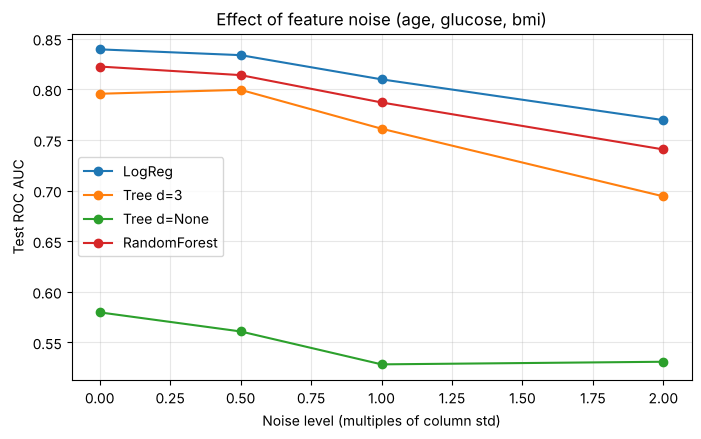

In [15]:
levels = [0, 0.5, 1, 2]
col_std = X_train[num_cols].std()            # std of the clean train columns
feat_rows = {}
for lv in levels:
    reps = 1 if lv == 0 else 5
    runs = []
    for r in range(reps):
        rng = np.random.default_rng(SEED + r)
        Xn = X_train.copy()
        for c in num_cols:
            Xn[c] = Xn[c] + rng.normal(size=len(Xn)) * col_std[c] * lv
        runs.append(fit_score_zoo(Xn, y_train, X_test))      # test untouched; scaler fitted on noisy train
    feat_rows[lv] = pd.DataFrame(runs).mean()
feat_tab = pd.DataFrame(feat_rows).T
feat_tab.index.name = "feature noise level (x std)"
display(feat_tab)

feat_tab.plot(marker="o", figsize=(8, 4.5))
plt.ylabel("Test ROC AUC"); plt.xlabel("Noise level (multiples of column std)")
plt.title("Effect of feature noise (age, glucose, bmi)"); plt.grid(alpha=.3); plt.show()

### Task 5.3 — SMOTE and noisy labels (10% flipped, 3 random draws)

In [16]:
rows53 = []
for draw in range(3):
    rng = np.random.default_rng(SEED + draw)
    y_noisy = pd.Series(flip_labels(y_train, 0.10, rng), index=y_train.index)
    for mname, (maker, Xtr_, Xte_) in setups.items():
        for use_smote in [False, True]:
            if use_smote:
                Xr, yr = SMOTE(random_state=SEED).fit_resample(Xtr_, y_noisy)   # SMOTE AFTER the noise is added
            else:
                Xr, yr = Xtr_, y_noisy
            r = evaluate(maker(), Xr, yr, Xte_, y_test)
            rows53.append({"draw": draw, "Model": mname, "SMOTE": "with SMOTE" if use_smote else "no SMOTE",
                           "PR_AUC": r["PR_AUC"], "ROC_AUC": r["ROC_AUC"]})
raw53 = pd.DataFrame(rows53)
tab53 = raw53.groupby(["Model", "SMOTE"])[["PR_AUC", "ROC_AUC"]].agg(["mean", "std"])
display(tab53)
print("Clean-label reference (no noise, no SMOTE):")
display(pd.DataFrame({m: {k: store41[(m, "No resampling")][k] for k in ["PR_AUC", "ROC_AUC"]}
                      for m in ["LogReg", "RandomForest"]}).T)

PR_AUC        ROC_AUC       
                          mean    std    mean    std
Model        SMOTE                                  
LogReg       no SMOTE    0.217  0.028   0.814  0.004
             with SMOTE  0.226  0.026   0.816  0.004
RandomForest no SMOTE    0.154  0.033   0.748  0.021
             with SMOTE  0.061  0.005   0.597  0.027

Clean-label reference (no noise, no SMOTE):


,PR_AUC,ROC_AUC
LogReg,0.269,0.839
RandomForest,0.226,0.822


**Interpretation of Parts 5.1 and 5.2.** Test ROC AUC (average over 5 random repeats; clean = no noise):

| Label noise | LogReg | Tree d=3 | Tree d=None | RandomForest |
|---|---|---|---|---|
| 0 | 0.839 | 0.796 | 0.580 | 0.822 |
| 0.20 | 0.774 | 0.726 | 0.505 | 0.683 |

| Feature noise (x std) | LogReg | Tree d=3 | Tree d=None | RandomForest |
|---|---|---|---|---|
| 0 | 0.839 | 0.796 | 0.580 | 0.822 |
| 2 | 0.770 | 0.694 | 0.531 | 0.741 |

All models get worse as noise grows. The deep tree starts at only 0.580 and is close to random (0.5) for every noise level, so it has little left to lose.

**Answer 5(a) — Most damaged and most stable**

At the highest label-noise level (20% flipped) the drops in AUC are: LogReg 0.839 -> 0.774 (**-0.065**), Tree d=3 0.796 -> 0.726 (-0.070), Tree d=None 0.580 -> 0.505 (-0.075, but starting from a nearly useless level) and **Random Forest 0.822 -> 0.683 (-0.139)**. So the **Random Forest is the most damaged** and **Logistic Regression is the most stable** (and still the best, 0.774). With 20% flips about 780 healthy patients become fake "strokes" and about 40 real strokes are erased, so most training "strokes" are wrong. This links to Part 2: Logistic Regression is a **high-bias, low-variance** model; it cannot bend to follow individual mislabelled points and keeps the overall trend. The forest is a **low-bias, high-variance** learner (deep trees with only 5 rows per leaf): it has enough flexibility to *fit the wrong labels*, and averaging helps against random variance but not against systematic, wrong targets. The unpruned tree is already overfitted without noise (CV 0.564 in Part 2), so noise barely changes it. At the highest feature-noise level (2x std) the drops are LogReg -0.069, Tree d=3 -0.102, Tree d=None -0.049 (from 0.580), Random Forest -0.081.

**Answer 5(b) — Label noise or feature noise?**

At a comparable level the two are roughly equal overall, but label noise is somewhat worse: averaged over the three informative models (LogReg, Tree d=3, RF), 20% label noise costs about 0.091 AUC and 2x-std feature noise about 0.084. The pattern differs by model: label noise hurts the flexible Random Forest most (-0.139 vs -0.081), while feature noise hurts the shallow tree most (-0.102 vs -0.070), because its few splits on age/glucose thresholds are exactly the values that get blurred. Logistic Regression is similarly affected by both (-0.065 vs -0.069). A short reason: wrong labels give the model a *wrong target*, which a flexible model will happily learn, whereas noisy features only blur the signal (the noise is not correlated with the label), so the damage is more limited.

**Answer 5(c) — SMOTE with 10% noisy labels (3 draws, mean)**

| Model | PR AUC without SMOTE | PR AUC with SMOTE | ROC AUC without | ROC AUC with |
|---|---|---|---|---|
| LogReg | 0.217 | 0.226 | 0.814 | 0.816 |
| RandomForest | 0.154 | **0.061** | 0.748 | **0.597** |

For **Logistic Regression SMOTE made practically no difference** (PR +0.009, ROC +0.002, both within the draw-to-draw std of about 0.03 and 0.004), again because the model only shifts its intercept. For **Random Forest SMOTE was harmful: PR AUC fell from 0.154 to 0.061 (about the no-skill level of 0.049) and ROC AUC from 0.748 to 0.597**, much worse than with clean labels (RF+SMOTE ROC 0.767, PR 0.119, Part 4). **Why SMOTE amplifies label noise:** with 10% flips, the "stroke" class consists of roughly 20% real strokes and 80% healthy patients wrongly labelled, scattered all over the feature space. SMOTE trusts every minority label: it interpolates between these points, creating thousands of new synthetic "strokes" in regions that are really healthy and, by joining real strokes with wrongly labelled neighbours, in between the two groups. The noise is multiplied, the class becomes 50% polluted and the forest memorises it. Rebalancing methods should therefore be used only after labels have been checked/cleaned.

## Part 6 — Final Decision and Conclusion

In [17]:
# Final choice: Logistic Regression (scaled) + decision threshold learned from out-of-fold TRAIN probabilities
def final_metrics(proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Threshold": threshold, "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred, zero_division=0),
            "Flagged patients": int(pred.sum()), "False alarms (FP)": int(fp), "Missed strokes (FN)": int(fn),
            "Caught strokes (TP)": int(tp)}

final_tab = pd.DataFrame({"Default threshold 0.5": final_metrics(p_lr, 0.5),
                          "Chosen threshold (OOF, recall>=0.80)": final_metrics(p_lr, thr)}).T
display(final_tab)

,Threshold,Precision,Recall,F1,Flagged patients,False alarms (FP),Missed strokes (FN),Caught strokes (TP)
Default threshold 0.5,0.500,1.000,0.02,0.039,1.0,0.0,49.0,1.0
"Chosen threshold (OOF, recall>=0.80)",0.051,0.135,0.82,0.232,303.0,262.0,9.0,41.0


In [18]:
# uncertainty of the test recall: 95% Wilson interval (only 50 stroke patients in the test set)
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half
k, n = int(final_tab.loc["Chosen threshold (OOF, recall>=0.80)", "Caught strokes (TP)"]), int(y_test.sum())
lo, hi = wilson(k, n)
print("Recall = %d/%d = %.2f, 95%% Wilson interval: [%.2f, %.2f]" % (k, n, k / n, lo, hi))
print("Cost per caught stroke: %.1f false alarms" % (final_tab.loc["Chosen threshold (OOF, recall>=0.80)", "False alarms (FP)"] / k))

Recall = 41/50 = 0.82, 95% Wilson interval: [0.69, 0.90]
Cost per caught stroke: 6.4 false alarms


**Interpretation.** At the default threshold 0.5 the model flags 1 patient, catches 1 stroke and misses 49 (precision 1.0 is meaningless, F1 0.039). At the chosen threshold 0.051 it flags 303 patients, catches 41 strokes, misses 9, and creates 262 false alarms (F1 0.232). The recall interval shows how uncertain the test recall is: **0.82, 95% interval 0.69-0.90**, because it is based on only 50 strokes.

### Executive Summary

I chose **Logistic Regression on standardised features with the decision threshold lowered from 0.5 to 0.051**; the threshold is the highest value giving at least 80% recall on out-of-fold probabilities computed on the training data only. On the held-out test set (1,022 patients, 50 strokes) it catches **41 of 50 strokes (recall 0.82)** with **precision 0.135** (F1 0.232; ROC AUC 0.839, PR AUC 0.269 against a no-skill level of 0.049), compared with 1 of 50 at the default threshold. The price is **303 flagged patients (29.6%), of which 262 are false alarms (about 6.4 per stroke found)**; 9 strokes are still missed. Leakage was avoided by splitting first (stratified), fitting the median imputer and the scaler on the training data only (the scaler sits inside a pipeline for the cross-validated threshold), resampling only the training data, choosing the threshold on training data only and touching the test set only for reporting; the SMOTE-before-split experiment showed how leakage inflates results (ROC AUC 0.981 vs 0.767). A key **limitation** is that 50 test strokes make the recall very uncertain (95% interval 0.69-0.90, one patient = 2 points), the threshold of 0.051 was tuned on only 199 training strokes and would shift with another split or population, and there is no external validation; the model should be used as a cheap first-stage screen, not as a diagnosis.

### Final Reflection

**(a) Most surprising result:** that Logistic Regression had a *better* accuracy than the baseline (0.952 vs 0.951) while finding only 1 stroke out of 50, and that, on the other side, the leaky SMOTE-before-split experiment produced an almost perfect ROC AUC of 0.981 for the same Random Forest that reaches only 0.767 honestly. A second surprise: SMOTE helped nothing for Logistic Regression and hurt the Random Forest badly when labels were noisy (ROC AUC 0.748 -> 0.597).

**(b) With one more hour I would try:** (1) repeated stratified cross-validation (or bootstrap) to get confidence intervals for recall and for the chosen threshold, because 50 test strokes is very few; (2) probability calibration (Platt/isotonic) and a cost-based threshold using an explicit cost ratio between a missed stroke and a false alarm; (3) gradient boosting with class weights and a regularised Random Forest tuned on PR AUC; (4) a better imputation of `bmi` and feature engineering (e.g. age x hypertension / glucose interactions).